<a href="https://colab.research.google.com/github/Simone-Prado/Aula-Github/blob/main/Avalia%C3%A7aoII_Versao_2(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Avaliação II – Aprendizado de Máquina
## Etapa 1: Proposta de projeto de aprendizado de máquina

**Integrantes:**
- Nome: Carla Aparecida Harada Hirata — Termo: 2º IA
- Nome: Simone Batista do Prado       — Termo:  2º IA

## 1. Problema e aplicação

**Problema:** identificar, com antecedência, alunos com risco de baixo desempenho acadêmico, a partir de informações como tempo de estudo, faltas, reprovações anteriores e notas parciais.

**Quem poderia usar e para quê:**
- **Coordenações de curso e setores de apoio ao estudante**, para direcionar monitorias, tutorias e acompanhamento pedagógico aos alunos com maior risco antes do fim do ano letivo.
- **Professores**, para entender quais hábitos (como frequência e tempo de estudo) estão mais associados ao bom desempenho e orientar os alunos.
- **Instituições de ensino**, para planejar ações de prevenção à reprovação e à evasão.

O resultado seria uma ferramenta de **apoio à decisão**, e não de avaliação individual: o objetivo é oferecer ajuda a quem precisa, não rotular ou punir alunos.

## 2. Dataset e origem

- **Nome:** Student Performance Dataset
- **Link:** https://www.kaggle.com/datasets/larsen0966/student-performance-data-set
- **Arquivo utilizado:** `student-por.csv`
- **Descrição:** dados de 649 alunos do ensino secundário de duas escolas públicas portuguesas (Gabriel Pereira e Mousinho da Silveira), na disciplina de Português. Reúne informações demográficas, familiares, sociais e escolares (tempo de estudo, reprovações anteriores, faltas), além das notas dos três períodos (G1, G2 e G3, escala de 0 a 20).
- **Origem dos dados:** dados reais coletados por questionários e registros escolares publicados originalmente por Paulo Cortez e Alice Silva (Universidade do Minho, 2008) e disponíveis também no UCI Machine Learning Repository.



In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from google.colab import files

arquivos = files.upload()
dados = pd.read_csv("student-por.csv")
display(dados.head())
print("Linhas e colunas:", dados.shape)
print("Valores ausentes:\n", dados.isna().sum())
print("Duplicatas:", dados.duplicated().sum())

Saving student-por.csv to student-por (1).csv


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


Linhas e colunas: (649, 33)
Valores ausentes:
 school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64
Duplicatas: 0


## 3. Conhecimento da Base

A partir da execução dos comandos exploratórios no ecossistema de dados, mapeamos as seguintes características estruturais da nova base de dados de Portugal:

* **Dimensões do Dataset:** A tabela é composta por **649 linhas (registros de alunos)** e **33 colunas (atributos/variáveis)**.

* **Variáveis utilizadas:** a base possui 33 colunas. Para esta proposta, foram selecionadas as variáveis abaixo.

| Coluna | Significado | Valores |
|---|---|---|
| age | Idade do aluno | 15 a 22 anos |
| traveltime | Tempo de trajeto até a escola | 1 = menos de 15 min · 2 = 15 a 30 min · 3 = 30 min a 1 h · 4 = mais de 1 h |
| studytime | Tempo de estudo semanal fora da aula | 1 = menos de 2 h · 2 = 2 a 5 h · 3 = 5 a 10 h · 4 = mais de 10 h |
| failures | Reprovações anteriores | 0 a 3 (3 = três ou mais) |
| absences | Número de faltas | 0 a 32 |
| G1 | Nota do 1º período | 0 a 20 |
| G2 | Nota do 2º período | 0 a 20 |
| G3 | Nota final (base da variável alvo) | 0 a 20 |
| desempenho | Variável alvo criada a partir de G3 | "Alto" (G3 ≥ 10) ou "Baixo" (G3 < 10) |

As demais colunas (escola, sexo, escolaridade dos pais, apoio familiar, entre outras) são majoritariamente categóricas e não foram utilizadas nesta etapa.


* **Qualidade dos Dados (Valores Ausentes e Duplicados):** O método `.isna().sum()` confirmou a total ausência de valores nulos, indicando uma base completamente preenchida. Além disso, o método `.duplicated().sum()` retornou zero, comprovando que não existem registros identicamente repetidos no conjunto de dados.
* **Equilíbrio da Variável Alvo:** Após a transformação da nota final `G3` usando o ponto de corte oficial de aprovação de Portugal (nota maior ou igual a 10), o conjunto de treino apresentou as seguintes proporções:
  * **Alto Desempenho (Aprovados):** 439 estudantes.
  * **Baixo Desempenho (Reprovados):** 80 estudantes.
  
*Nota de Análise: Esta base real de Língua Portuguesa apresenta um desbalanceamento natural (a grande maioria dos alunos consegue a aprovação). Esse comportamento é típico de cenários escolares reais e exigirá atenção do modelo de classificação para garantir uma boa taxa de acerto também na classe minoritária (Baixo Desempenho).*

--- Divisão Definitiva dos Dados ---
Registros para Treino (80%): 519
Registros para Validação (20%): 130

Equilíbrio das classes no Treino:
desempenho
Alto     439
Baixo     80
Name: count, dtype: int64

Resumo estatístico das variáveis de entrada (treino):


,age,traveltime,studytime,failures,absences,G1,G2
count,519.0,519.0,519.0,519.0,519.0,519.0,519.0
mean,16.7,1.6,1.9,0.2,3.8,11.5,11.6
std,1.2,0.8,0.8,0.6,4.7,2.7,2.9
min,15.0,1.0,1.0,0.0,0.0,0.0,0.0
25%,16.0,1.0,1.0,0.0,0.0,10.0,10.0
50%,17.0,1.0,2.0,0.0,2.0,11.0,11.0
75%,18.0,2.0,2.0,0.0,6.0,13.0,13.0
max,22.0,4.0,4.0,3.0,32.0,19.0,18.0



Mediana dos atributos por perfil de desempenho:


,age,traveltime,studytime,failures,absences,G1,G2
desempenho,,,,,,,
Alto,17.0,1.0,2.0,0.0,2.0,12.0,12.0
Baixo,17.0,2.0,1.0,1.0,2.0,8.0,8.0


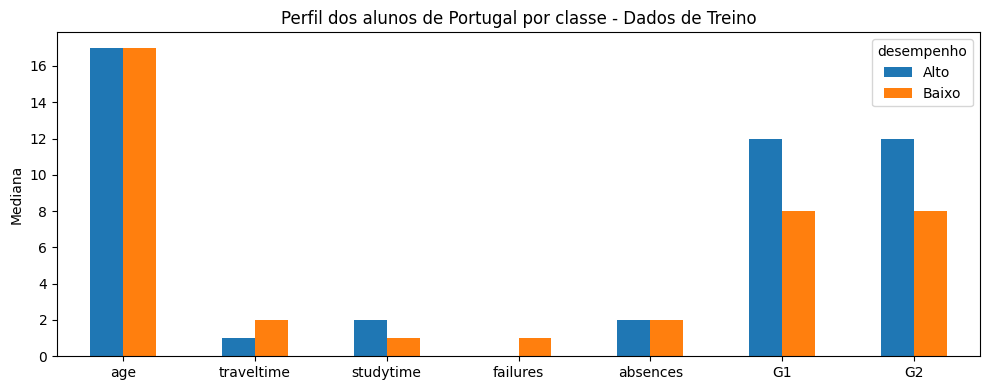

In [ ]:
from sklearn.model_selection import train_test_split
# 1. Criação do Alvo Baseado na Nota Final (G3)
# Em Portugal a nota vai de 0 a 20. O critério oficial de aprovação lá é nota >= 10.
dados["desempenho"] = dados["G3"].apply(lambda nota: "Alto" if nota >= 10 else "Baixo")

# 2. Seleção Estratégica de Features (Cenário A - Com alto sinal preditivo)
# Escolhemos as notas parciais (G1, G2) e variáveis de comportamento/sociais importantes
colunas_numéricas = ["age", "traveltime", "studytime", "failures", "absences", "G1", "G2"]

# 3. Separação Definitiva em X e y
X = dados[colunas_numéricas]
y = dados["desempenho"]

# 4. Split Único e Definitivo (80% treino / 20% validação com estratificação)
X_treino, X_validacao, y_treino, y_validacao = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("--- Divisão Definitiva dos Dados ---")
print("Registros para Treino (80%):", len(X_treino))
print("Registros para Validação (20%):", len(X_validacao))
print("\nEquilíbrio das classes no Treino:")
print(y_treino.value_counts())
print("\nResumo estatístico das variáveis de entrada (treino):")
display(X_treino.describe().round(1))

# 5. Análise dos Perfis (Mediana) por classe usando os dados de treino
perfis = X_treino.assign(desempenho=y_treino).groupby("desempenho").median()
print("\nMediana dos atributos por perfil de desempenho:")
display(perfis.round(1))

# 6. Gráfico de Perfil
perfis.T.plot.bar(figsize=(10, 4), rot=0)
plt.ylabel("Mediana")
plt.title("Perfil dos alunos de Portugal por classe - Dados de Treino")
plt.tight_layout()
plt.show()

**Leitura dos perfis:** os alunos com alto desempenho estudam, em mediana, de 2 a 5 horas por semana (faixa 2), contra menos de 2 horas dos alunos com baixo desempenho (faixa 1). Os alunos com baixo desempenho também têm, em mediana, uma reprovação anterior e notas parciais 4 pontos menores (8 contra 12).

## 4. Objetivo da Previsão

* **Coluna que será prevista:** O objetivo central é prever a variável alvo `desempenho`. Essa coluna foi criada e discretizada de forma customizada a partir da coluna original `G3` (Nota Final), dividindo os estudantes entre rendimento "Alto" e "Baixo".
* **Tipo de problema:** Trata-se de um problema de **Classificação Binária**, uma vez que a variável predita possui natureza categórica e restrita a duas classes possíveis distintas.
* **Variáveis de Entrada (Features):** Para mapear e alimentar o modelo de aprendizado de máquina, serão utilizadas as seguintes variáveis de entrada:
  * Age:  Idade
  * Traveltime: Tempo de trajeto até a escola
  * Studytime: Tempo dedicado ao estudo fora do período de aulas
  * Failures: Reprovações históricas
  * Absences: Faltas
  * G1: Nota do 1º Período
  * G2: Nota do 2º Período
  


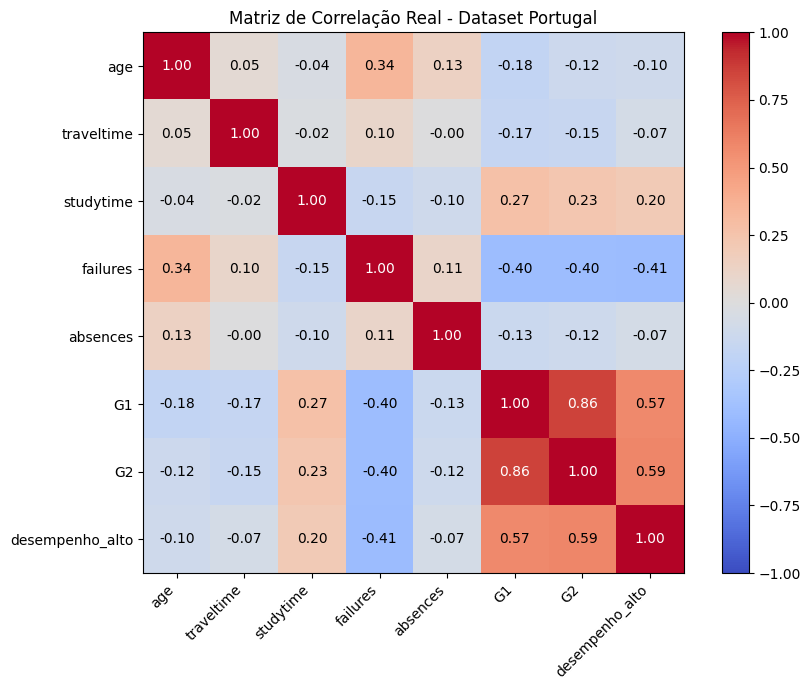

In [ ]:
# 1. Prepara a tabela numérica convertendo o alvo para binário (0 e 1)
tabela = X_treino.assign(desempenho_alto=(y_treino == "Alto").astype(int))

# 2. Calcula a correlação matemática de Pearson
correlacao = tabela.corr()
colunas = list(correlacao.columns)

# 3. Configura e desenha o Mapa de Calor (Heatmap)
fig, ax = plt.subplots(figsize=(9, 7))
imagem = ax.imshow(correlacao, cmap="coolwarm", vmin=-1, vmax=1)

# Configura as legendas dos eixos
ax.set_xticks(range(len(colunas)), colunas, rotation=45, ha="right")
ax.set_yticks(range(len(colunas)), colunas)

# Preenche os quadrados com os valores numéricos
for i in range(len(colunas)):
    for j in range(len(colunas)):
        valor = correlacao.iloc[i, j]
        ax.text(j, i, f"{valor:.2f}", ha="center", va="center",
                color="white" if abs(valor) > 0.6 else "black")

fig.colorbar(imagem, ax=ax)
ax.set_title("Matriz de Correlação Real - Dataset Portugal")
plt.tight_layout()
plt.show()

## 5. Plano Inicial

* **Modelo Candidato:** O modelo inicial proposto para o desenvolvimento do projeto será o algoritmo **K-Nearest Neighbors (KNN)** ou uma **Árvore de Decisão**.

* **Justificativa:** A nova base de dados real de Portugal apresenta um comportamento estatístico muito claro, com correlações lineares fortes entre as notas parciais (G1 e G2) e o desempenho final (G3). Algoritmos baseados em árvores são excelentes para este cenário, pois conseguem criar regras de quebra lógicas intuitivas (por exemplo, "Se a nota G2 for maior que X, classifique como Alto Desempenho"). Já o KNN é ideal por ser um modelo geométrico simples que tira proveito da proximidade dos perfis dos alunos no espaço de características para fazer a classificação, servindo como uma ótima linha de base.

* **Cenários de teste**: como as notas parciais G1 e G2 são fortemente correlacionadas com a nota final, o modelo será avaliado em dois cenários:

* 1. **Cenário A (com notas parciais)**: usa todas as variáveis selecionadas, incluindo G1 e G2. Deve apresentar desempenho alto, mas só é aplicável quando o ano letivo já está avançado.

* 2. **Cenário B (sem notas parciais)**: usa apenas idade, tempo de trajeto, tempo de estudo, reprovações anteriores e faltas. Representa a previsão realmente antecipada, feita no início do ano, quando ainda há tempo para intervenção pedagógica.

*   A comparação entre os dois cenários permitirá avaliar quanto do poder de previsão vem das notas e quanto vem dos hábitos e do histórico do aluno.

* **Dificuldades Previstas:**
  1. **Ajuste de Escala (Normalização):** Como pretendemos manter variáveis de comportamento (como o número de faltas `absences`, que acumula valores maiores) junto com notas (escala de 0 a 20) e dados menores (como tempo de estudo `studytime`, de 1 a 4), o algoritmo KNN pode ser severamente distorcido pelo tamanho bruto dos números. Será obrigatório aplicar técnicas de escalonamento, como o `MinMaxScaler` ou `StandardScaler`, antes de treinar o modelo.
  2. **Risco de Overfitting pelas Notas Parciais:** Devido à correlação extremamente alta entre as notas G1/G2 e a classe final (conforme observado na nova matriz de correlação), o modelo pode se tornar excessivamente dependente dessas duas colunas. O desafio será calibrar os hiperparâmetros (como a profundidade da árvore ou o número de vizinhos K) para garantir que a IA aprenda um padrão generalizável e não apenas "decore" o histórico recente de notas dos estudantes.
  3.  **Desbalanceamento das classes:** a base possui cerca de 85% de alunos com alto desempenho e 15% com baixo desempenho. Um modelo que classificasse todos como “Alto” já atingiria aproximadamente 85% de acurácia, sem identificar nenhum aluno em risco. Por isso, a acurácia não será a única métrica: serão priorizados o recall e o F1-score da classe “Baixo”, além da acurácia balanceada, já que o objetivo é justamente encontrar os alunos com risco de reprovação. Para a Árvore de Decisão, também será testado o parâmetro class_weight="balanced", que aumenta o peso da classe minoritária durante o treinamento.


DECLARAÇÃO DE USO DE INTELIGÊNCIA ARTIFICIAL

Declaramos que utilizamos ferramentas de Inteligência Artificial no desenvolvimento deste trabalho, conforme as especificações abaixo:

1.	Ferramenta utilizada: Gemini e Claude

2.	Finalidade: As ferramentas foram utilizadas para a localização de arquivos no Kaggle que atendesse aos requisitos necessários (dados reais ao invés de dados sintéticos), codificação das alterações no código em Python e para críticas finais do resultado, visando a correção de lacunas existentes

3.	Comandos (prompts) principais:  Foram anexados o enunciado do trabalho, e o trabalho elaborado para as críticas finais e correções.   


4.	Contribuição da IA para o resultado final:
As ferramentas foram essenciais para a escolha do dataset  fonte, pois só estávamos encontrando dados sintéticos e para as alterações no código base dado em sala de aula em função dos arquivos de dados serem sempre diferentes.

5.	Responsabilidade:
Declaramos que todas as informações e conteúdo gerados ou modificados pela(s) ferramenta(s) de Inteligência Artificial indicada(s) acima foram revisadas, validadas criticamente e checadas quanto à sua exatidão e fundamentação real. Assumimos responsabilidade integral pela autoria final, originalidade, integridade acadêmica e ético-científica do conteúdo deste trabalho, inclusive por eventuais plágios ou imprecisões.

